# MASSPEC (1970), step by step

Margaret O. Dayhoff and Richard V. Eck, "MASSPEC: A computer program for
complete sequence analysis of large proteins from mass spectrometry data of a
single sample", *Computers in Biology and Medicine* 1, 5-28 (1970),
[doi:10.1016/0010-4825(70)90013-2][doi].

[doi]: https://doi.org/10.1016/0010-4825(70)90013-2

Their proposal: break a protein near-randomly (partial acid hydrolysis), make
the fragments volatile, and measure the whole mixture in **one**
high-resolution mass spectrum. An exact mass fixes a fragment's elemental
formula but not its sequence, nor even its amino acid composition (Ala-Val and
Gly-Leu weigh the same). The sequence is recovered as the one set of
overlapping fragments that is mutually consistent among the thousands of
spurious candidates the same masses also allow.

They demonstrated it on simulated, ideal data for bovine insulin. This notebook
redoes that experiment with the reimplementation in this repository
(`src/masspec`), one program at a time, and regenerates each figure of the
paper next to the values the paper prints. **The code is a reimplementation
from the paper's description, not the original program, which appears to be
lost.**

The paper's one-letter code is used throughout: **J** is leucine or isoleucine
(they weigh the same, so the method cannot tell them apart) and **O** is
tyrosine.

In [1]:
import random
from itertools import combinations_with_replacement

import matplotlib.pyplot as plt

from masspec.fragments import add_noise, fragen, ideal_masses
from masspec.masses import _FREE_1970, H2O, H2O_1970, MASSES, MASSES_1970
from masspec.mspec import (
    Observed,
    canon,
    cq,
    masfrg,
    overlap_step,
    prune,
    run,
)


def peptide_mass(residues):
    # peptide mass: residues plus one water
    return sum(MASSES_1970[residue] for residue in residues) + H2O_1970


def composition(residues):
    # composition, letters in alphabetical order
    return "".join(sorted(residues))


def difference(first, second):
    # first - second, rounded to the five decimals the paper prints. Adding
    # 0.0 turns a negative zero (a leftover such as -1e-12) into a plain 0.
    return round(first - second, 5) + 0.0


# insulin A chain, bovine (21 residues)
INSULIN_A = "GJVEQCCASVCSJOQJENOCN"
# insulin B chain, bovine (30 residues)
INSULIN_B = "FVNQHJCGSHJVEAJOJVCGERGFFOTPKA"

## Fig. 2: the masses

The paper lists the monoisotopic masses of the free amino acids; a peptide
weighs their sum minus one water per peptide bond, which is the same as the sum
of RESIDUE masses plus one water. Below, the paper's values beside present-day
ones (free amino acid = residue + water).

One entry is wrong in the paper: tryptophan is printed as 188.09489, but free
tryptophan (C11H12N2O2) weighs 204.0899. The program evidently ran on the
printed value, because the counts in Figs. 6-8 are only reproduced with it (see
below). Insulin has no tryptophan, so the slip never showed.

In [2]:
# Fig. 2's rows, in its order. It also lists Ile (I) and Leu (L), with the
# same mass as J; the program itself only uses J.
ACIDS = {
    "A": "Ala", "C": "Cys", "E": "Glu", "F": "Phe", "G": "Gly", "D": "Asp",
    "H": "His", "J": "Lux (Ile or Leu)", "K": "Lys", "M": "Met",
    "N": "Asn", "O": "Tyr", "P": "Pro", "Q": "Gln", "R": "Arg", "S": "Ser",
    "T": "Thr", "V": "Val", "W": "Trp",
}
modern = {"J": MASSES["L"], "O": MASSES["Y"], **MASSES}
print(
    f"{'Acid':<18}{'Code':<6}{'Mass':>11}{'Present-Day':>13}"
    f"{'Difference':>12}"
)
for code, acid in ACIDS.items():
    now = modern[code] + H2O  # free amino acid = residue + water
    printed = _FREE_1970[code]
    gap = difference(printed, now)
    print(f"{acid:<18}{code:<6}{printed:11.5f}{now:13.5f}{gap:12.5f}")
water_gap = difference(H2O_1970, H2O)
print(f"{'H2O':<24}{H2O_1970:11.5f}{H2O:13.5f}{water_gap:12.5f}")

Acid              Code         Mass  Present-Day  Difference
Ala               A        89.04763     89.04768    -0.00005
Cys               C       121.01970    121.01975    -0.00005
Glu               E       147.05309    147.05316    -0.00007
Phe               F       165.07891    165.07898    -0.00007
Gly               G        75.03199     75.03203    -0.00004
Asp               D       133.03745    133.03751    -0.00006
His               H       155.06941    155.06948    -0.00007
Lux (Ile or Leu)  J       131.09455    131.09463    -0.00008
Lys               K       146.10544    146.10553    -0.00009
Met               M       149.05098    149.05105    -0.00007
Asn               N       132.05343    132.05349    -0.00006
Tyr               O       181.07382    181.07389    -0.00007
Pro               P       115.06327    115.06333    -0.00006
Gln               Q       146.06907    146.06914    -0.00007
Arg               R       174.11158    174.11168    -0.00010
Ser               S     

## Fig. 1: FRAGEN, fragmenting the protein

FRAGEN simulates a random hydrolysis by listing every fragment of the chain.
The masses will only say what a fragment is MADE of, so the paper prints the
amino acid composition of each, in alphabetical order. Fig. 1 shows the 24
fragments seven residues long from the B chain (the paper writes L for Leu
here, J elsewhere).

In [3]:
def as_printed(residues):
    # a composition as Figs. 1, 3 and 4 print it: L for J, letters spaced
    return " ".join(residues.replace("J", "L"))


print("Structure of Initial Polymer, Bovine Insulin\n")
print("A chain - " + " ".join(INSULIN_A))
print("B chain - " + " ".join(INSULIN_B))
print("\nFragments from B Chain\n")
print(f"{'Fragments of Length 7':>21}   Amino Acid Composition")
seven = [INSULIN_B[start:start + 7] for start in range(len(INSULIN_B) - 6)]
for number, fragment in enumerate(seven, 1):
    print(f"{number:21}   {as_printed(composition(fragment))}")

Structure of Initial Polymer, Bovine Insulin

A chain - G J V E Q C C A S V C S J O Q J E N O C N
B chain - F V N Q H J C G S H J V E A J O J V C G E R G F F O T P K A

Fragments from B Chain

Fragments of Length 7   Amino Acid Composition
                    1   C F H L N Q V
                    2   C G H L N Q V
                    3   C G H L N Q S
                    4   C G H H L Q S
                    5   C G H H L L S
                    6   C G H L L S V
                    7   C E G H L S V
                    8   A E G H L S V
                    9   A E H L L S V
                   10   A E H L L O V
                   11   A E L L L O V
                   12   A E L L O V V
                   13   A C E L L O V
                   14   A C G L L O V
                   15   C E G L L O V
                   16   C E G L O R V
                   17   C E G G L R V
                   18   C E F G G R V
                   19   C E F F G G R
                   20   E F F G G O R


## Figs. 3 and 4: MASFRG, the masses of the fragments

MASFRG computes each fragment's mass. Fig. 3 lists the B chain's dipeptides,
Fig. 4 its octapeptides; the paper's values are copied below.

In [4]:
paper_fig3 = {
    "AE": 218.09016, "AK": 217.14251, "AJ": 202.13162, "CG": 178.04113,
    "CJ": 234.10369, "CV": 220.08805, "EG": 204.07452, "ER": 303.15411,
    "EV": 246.12144, "FF": 312.14725, "FG": 222.10034, "FO": 328.14217,
    "FV": 264.14726, "GR": 231.13301, "GS": 162.06397, "HJ": 268.15340,
    "HQ": 283.12791, "HS": 242.10139, "KP": 243.15815, "JO": 294.15781,
    "JV": 230.16290, "NQ": 260.11193, "NV": 231.12178, "OT": 282.12144,
    "PT": 216.11089,
}


def paper_order(residues):
    # Fig. 3 sorts its rows as printed, with L for J: AE, AK, AL, CG...
    return residues.replace("J", "L")


dipeptides = sorted(
    {
        composition(INSULIN_B[start:start + 2])
        for start in range(len(INSULIN_B) - 1)
    },
    key=paper_order,
)
print("Peptides Two Amino Acids Long\n")
print(
    f"{'':3}{'Mass':>12}{'Paper':>12}{'Difference':>12}"
    "   Amino Acid Composition of Peptide"
)
for number, dipeptide in enumerate(dipeptides, 1):
    here = peptide_mass(dipeptide)
    printed = paper_fig3[dipeptide]
    gap = difference(here, printed)
    print(
        f"{number:3}{here:12.5f}{printed:12.5f}{gap:12.5f}"
        f"   {as_printed(dipeptide)}"
    )

Peptides Two Amino Acids Long

           Mass       Paper  Difference   Amino Acid Composition of Peptide
  1   218.09016   218.09016     0.00000   A E
  2   217.14251   217.14251     0.00000   A K
  3   202.13162   202.13162     0.00000   A L
  4   178.04113   178.04113     0.00000   C G
  5   234.10369   234.10369     0.00000   C L
  6   220.08805   220.08805     0.00000   C V
  7   204.07452   204.07452     0.00000   E G
  8   303.15411   303.15411     0.00000   E R
  9   246.12144   246.12144     0.00000   E V
 10   312.14726   312.14725     0.00001   F F
 11   222.10034   222.10034     0.00000   F G
 12   328.14217   328.14217     0.00000   F O
 13   264.14726   264.14726     0.00000   F V
 14   231.13301   231.13301     0.00000   G R
 15   162.06397   162.06397     0.00000   G S
 16   268.15340   268.15340     0.00000   H L
 17   283.12792   283.12791     0.00001   H Q
 18   242.10139   242.10139     0.00000   H S
 19   243.15815   243.15815     0.00000   K P
 20   294.15781   2

In [5]:
paper_fig4 = [
    916.42204, 856.38567, 894.37617, 893.41729, 864.42713, 856.41081,
    814.36389, 824.43874, 930.48057, 956.53258, 918.54208, 908.46723,
    866.42031, 866.42031, 951.48426, 895.42170, 879.42679, 913.41115,
    977.40606, 975.44454, 1015.47582, 1014.52817, 929.46422,
]
eight = [INSULIN_B[start:start + 8] for start in range(len(INSULIN_B) - 7)]
print("Peptides Eight Amino Acids Long\n")
print(
    f"{'':3}{'Mass':>12}{'Paper':>12}{'Difference':>12}"
    "   Amino Acid Composition of Peptide"
)
for number, (fragment, printed) in enumerate(zip(eight, paper_fig4), 1):
    here = peptide_mass(fragment)
    gap = difference(here, printed)
    print(
        f"{number:3}{here:12.5f}{printed:12.5f}{gap:12.5f}"
        f"   {as_printed(composition(fragment))}"
    )

Peptides Eight Amino Acids Long

           Mass       Paper  Difference   Amino Acid Composition of Peptide
  1   916.42205   916.42204     0.00001   C F G H L N Q V
  2   856.38568   856.38567     0.00001   C G H L N Q S V
  3   894.37618   894.37617     0.00001   C G H H L N Q S
  4   893.41730   893.41729     0.00001   C G H H L L Q S
  5   864.42714   864.42713     0.00001   C G H H L L S V
  6   856.41082   856.41081     0.00001   C E G H L L S V
  7   814.36390   814.36389     0.00001   A C E G H L S V
  8   824.43875   824.43874     0.00001   A E G H L L S V
  9   930.48058   930.48057     0.00001   A E H L L O S V
 10   956.53259   956.53258     0.00001   A E H L L L O V
 11   918.54209   918.54208     0.00001   A E L L L O V V
 12   908.46724   908.46723     0.00001   A C E L L O V V
 13   866.42032   866.42031     0.00001   A C E G L L O V
 14   866.42032   866.42031     0.00001   A C E G L L O V
 15   951.48427   951.48426     0.00001   C E G L L O R V
 16   895.42171   895

Every mass agrees with the paper to one unit in the fifth decimal: 22 of the
25 dipeptides exactly (FF, HQ and NQ are one unit lower in the paper), and
every octapeptide one unit lower in the paper.
Rounding rules alone cannot explain that: every mass in Fig. 2 has five
decimals, so these sums have no sixth digit to round or truncate. The original
program evidently carried more digits than it printed. Fig. 2 itself is
computed from elemental formulas with C = 12, H = 1.00782, N = 14.00307, O =
15.99491 and S = 31.97207 (all 18 values come out exactly), and the dipeptides
of Fig. 3 and the tetrapeptides of Fig. 5 all match if the water it subtracts
is 18.010565 rather than the printed 18.01056; the octapeptides fit no single
value. The rest is presumably the floating-point arithmetic of a 1970 machine,
which cannot be recovered from the printed numbers. The table also shows why
the method is hard: rows 13 and 14 are the same composition, and many different
peptides share a mass.

## Fig. 5: PEPMS, the table of all peptide masses

To go back from a mass to what could have made it, the program needs every
composition sorted by mass. PEPMS tabulates them (only up to four residues:
longer ones are generated later, from overlaps). Fig. 5 shows the stretch from
506.24 to 507.27. Each line is a group of compositions with identical formulas;
the step column is the gap to the previous mass. Unlike Figs. 1 and 4, which
are alphabetical, Fig. 5 writes each composition lightest residue first: VNQF
is V (99) < N (114) < Q (128) < F (147). So does this table.

In [6]:
def lightest_first(residue):
    # Fig. 5's order within a composition: by residue mass, then letter.
    return (MASSES_1970[residue], residue)


table = {}
for length in range(1, 5):
    for residues in combinations_with_replacement(sorted(MASSES_1970), length):
        table.setdefault(round(peptide_mass(residues), 5), []).append(
            "".join(sorted(residues, key=lightest_first))
        )
window = sorted(value for value in table if 506.24 <= value <= 507.27)
print(
    f"{'Mass':>11}   {'Peptide Composition':<22}"
    "Increase in Mass from Preceding Entry"
)
previous = None
for group_mass in window:
    first, *others = table[group_mass]
    step = f"{group_mass - previous:.5f}" if previous else ""
    print(f"{group_mass:11.5f}   {first:<22}{step:>9}")
    for other in others:
        print(f"{'':11}   {other}")
    previous = group_mass
anfr_tjhh = difference(peptide_mass("ANFR"), peptide_mass("TJHH"))
jnnf_vnqf = difference(peptide_mass("JNNF"), peptide_mass("VNQF"))
print(f"\nANFR - TJHH = {anfr_tjhh:.5f}    JNNF - VNQF = {jnnf_vnqf:.5f}")

       Mass   Peptide Composition   Increase in Mass from Preceding Entry
  506.24864   JNNF                           
              VNQF
  506.25199   CKKE                    0.00335
              TQKM
  506.25268   PPFF                    0.00069
  506.25603   PJMF                    0.00335
  506.25938   JJMM                    0.00335
  506.25987   ANFR                    0.00049
              GQFR
              TJHH
  506.26322   TCKR                    0.00335
  506.27378   JJDF                    0.01056
              VJEF
  506.28501   VNKF                    0.01123
  506.28836   TKKM                    0.00335
  506.29624   GKFR                    0.00788
  506.31015   VJJO                    0.01391
  507.16327   CQEE                    0.85312
              DDQM
              NDEM
  507.17450   CDDR                    0.01123
  507.17854   TCDW                    0.00404
              SCEW
  507.19629   PNDO                    0.01775
  507.19716   CCJW                    

The groups are the paper's, entry for entry: VNQF with JNNF at 506.24863, TQKM
with CKKE, then PPFF, PJMF and JJMM, and ANFR, GQFR and TJHH together at
506.25986, the paper's own example of a degeneracy (identical elemental
formulas). Within a group the paper's order follows no rule we could find
(probably the order its program generated them); here it is alphabetical. The
masses here are one unit higher in the fifth decimal, for the
reason given under Fig. 4. At a resolution of 0.02 a.m.u. many of these
neighbouring groups also blur together.

## The input: one spectrum of ideal masses

The insulin problem: every fragment of both chains up to nine residues long,
each mass observed once, exactly, and nothing above 1000 a.m.u.

In [7]:
masses = ideal_masses(
    [INSULIN_A, INSULIN_B],
    max_len=9,
    mass_limit=1000.0,
    table=MASSES_1970,
    water=H2O_1970,
)
print(
    len(masses), "distinct masses, from", round(masses[0], 3),
    "to", round(masses[-1], 3),
)
observed = Observed(masses, tol_da=0.02)

302 distinct masses, from 75.032 to 995.463


## Fig. 6: MASFRG, from masses back to compositions

Every composition up to four residues whose mass lies within ±0.02 of an
observed mass. "There are actually only 45 true fragments 3 long. However,
their masses correspond to any of 197 amino acid compositions."

In [8]:
compositions = masfrg(observed, MASSES_1970, H2O_1970, max_len=4)
true_compositions = {
    length: {
        tuple(sorted(fragment))
        for fragment in fragen([INSULIN_A, INSULIN_B], 4)
        if len(fragment) == length
    }
    for length in range(1, 5)
}
print("Insulin of Beef 'A' and 'B'   Limits -.02 to +.02 a.m.u.\n")
for length in (1, 2, 3):
    listed = ["".join(residues) for residues in sorted(compositions[length])]
    print(f"There Are {len(listed)} Fragments of Length {length}")
    for row in range(0, len(listed), 10):
        chunk = listed[row:row + 10]
        print("   " + " ".join(f"{entry:<5}" for entry in chunk).rstrip())

Insulin of Beef 'A' and 'B'   Limits -.02 to +.02 a.m.u.

There Are 16 Fragments of Length 1
   A     C     E     F     G     H     J     K     N     O
   P     Q     R     S     T     V
There Are 66 Fragments of Length 2
   AC    AD    AE    AG    AJ    AK    AM    AS    AV    CC
   CG    CJ    CN    CO    CP    CQ    CR    CS    CV    DJ
   DQ    DS    DT    EG    EJ    EK    EN    EQ    ER    ES
   EV    FF    FG    FO    FV    GG    GJ    GR    GS    GT
   GV    HJ    HQ    HS    JO    JQ    JR    JS    JV    KN
   KP    MP    MQ    NO    NQ    NV    OQ    OT    PT    RT
   RW    SS    SV    SW    TT    TV
There Are 197 Fragments of Length 3
   AAA   AAD   AAM   AAV   ACC   ACD   ACG   ACS   ACV   ADG
   ADJ   ADR   ADS   ADV   AEG   AEJ   AER   AEV   AFP   AGH
   AGJ   AGM   AGN   AGO   AJM   AJO   AKN   AKP   AMP   AMS
   AMT   ANR   ARV   ARW   AST   ASV   ATT   ATW   AVV   CCQ
   CEG   CEK   CEQ   CER   CFJ   CGG   CGJ   CGP   CGS   CGT
   CGV   CHJ   CJO   CJP   CJR   CJS   CJ

In [9]:
print(f"\n{'Length':>6}{'Fragments':>11}{'True Ones':>11}{'Paper':>7}")
for length, paper in zip(range(1, 5), (16, 66, 197, None)):
    print(
        f"{length:6}{len(compositions[length]):11}"
        f"{len(true_compositions[length]):11}{paper if paper else '':>7}"
    )


Length  Fragments  True Ones  Paper
     1         16         16     16
     2         66         41     66
     3        197         42    197
     4        749         43       


**Why "Fragments" and "Paper" exceed "True Ones".** The first two count what
MASFRG returns: every composition whose mass lies within ±0.02 a.m.u. of an
observed mass. "True Ones" counts only the compositions of insulin's real
fragments. The rest are spurious, of two kinds: isomers, different residues
with the same elemental formula (AV = GL, VQ = JN), and near-isobars that fall
inside the ±0.02 window. Single residues have neither (the closest pair, Q and
K, are 0.036 apart), so all 16 are true. From there the spurious share grows
with length, because the number of possible compositions grows far faster than
the number of real fragments while the window stays as wide: 41 true among 66
dipeptides, 42 among 197 tripeptides, 43 among 749 tetrapeptides. The paper
puts it as "there are actually only 45 true fragments 3 long. However, their
masses correspond to any of 197 amino acid compositions." Insulin has 46
distinct tripeptides by our count; they make only 42 different compositions,
and a composition is all a mass can tell.

## Fig. 7: PRUNE

"If the peptide (F,G,H,I) is true in any of its possible permutations, there
must also be at least two of the following: (F,G,H), (F,G,I), (F,H,I),
(G,H,I)." A true fragment's sub-fragments are all in the data; a spurious
composition's often are not.

In [10]:
pruned = prune(compositions, min_subs=2)
for length in range(1, 5):
    print(
        f"length {length}: {len(compositions[length]):4} -> "
        f"{len(pruned[length]):4}"
    )
print(f"\ntripeptides after PRUNE: {len(pruned[3])} (paper: 93)")

length 1:   16 ->   16
length 2:   66 ->   56
length 3:  197 ->   93
length 4:  749 ->  111

tripeptides after PRUNE: 93 (paper: 93)


WEED, which removes compositions contained in no longer one, is not used: the
paper notes that the dipeptide list after the next step is "identical with the
previous list", i.e. that step ran on PRUNE's output. With WEED in between, the
next count comes out at 170 instead of 172.

## Fig. 8: CQ, from compositions to sequences

Each composition is expanded to every order of its residues, and a sequence of
length N is kept only if both sequences of length N-1 inside it (its first N-1
and its last N-1 residues) are kept. A mass carries no direction, so a sequence
and its reverse are one entry: "AEJ means both AEJ and JEA".

In [11]:
sequences = cq(pruned)
print("Insulin of Beef 'A' and 'B'   Limits -.02 to +.02\n=CQ=")
print("Completely Sequenced Fragments Which May Be Present")
for length in (1, 2, 3):
    listed = sorted(sequences[length])
    print()
    for row in range(0, len(listed), 10):
        chunk = listed[row:row + 10]
        print("   " + " ".join(f"{entry:<5}" for entry in chunk).rstrip())

Insulin of Beef 'A' and 'B'   Limits -.02 to +.02
=CQ=
Completely Sequenced Fragments Which May Be Present

   A     C     E     F     G     H     J     K     N     O
   P     Q     R     S     T     V

   AC    AE    AG    AJ    AK    AS    AV    CC    CG    CJ
   CN    CO    CP    CQ    CR    CS    CV    EG    EJ    EK
   EN    EQ    ER    ES    EV    FF    FG    FO    FV    GG
   GJ    GR    GS    GT    GV    HJ    HQ    HS    JO    JQ
   JR    JS    JV    KN    KP    NO    NQ    NV    OQ    OT
   PT    RT    SS    SV    TT    TV

   ACC   ACG   ACS   ACV   AEG   AEJ   AER   AEV   AGC   AGE
   AGJ   AJE   AJG   AJO   AKN   AKP   ASC   ASV   AVA   AVC
   AVE   AVS   CAC   CAG   CAS   CAV   CCQ   CGE   CGG   CGJ
   CGS   CGT   CGV   CJG   CJH   CJO   CJR   CJS   CJV   CNO
   COJ   CON   CQC   CQE   CRE   CRJ   CRT   CSG   CSJ   CSS
   CSV   CVG   CVJ   CVS   CVT   EAG   EAJ   EAV   EGG   EGJ
   EGR   EGS   EGV   EJG   EJQ   EJR   EJV   ENO   ENV   EQJ
   ERG   ERJ   ESG   ESH   ESS   

In [12]:
true_sequences = {
    length: {
        canon(fragment)
        for fragment in fragen([INSULIN_A, INSULIN_B], 4)
        if len(fragment) == length
    }
    for length in range(1, 5)
}
print(
    f"{'Length':>6}{'Sequences':>11}{'True Ones':>11}{'True Kept':>11}"
    f"{'Paper':>7}"
)
for length, paper in zip(range(1, 5), (16, 56, 172, None)):
    kept = sequences[length] & true_sequences[length]
    print(
        f"{length:6}{len(sequences[length]):11}"
        f"{len(true_sequences[length]):11}{len(kept):11}"
        f"{paper if paper else '':>7}"
    )

Length  Sequences  True Ones  True Kept  Paper
     1         16         16         16     16
     2         56         41         41     56
     3        172         46         46    172
     4        259         45         45       


The paper gives 172 tripeptides in its caption, and 56 dipeptides implicitly:
its dipeptide list after CQ is "identical with the previous list (Fig. 7)",
which is PRUNE's 56. Every true sequence survives CQ (41, 46 and 45 of them),
so nothing real has been lost yet; what CQ removes is orderings of spurious
compositions that the masses of their own sub-sequences contradict.

## Figs. 9 to 11: OVERLAP, growing the chain

From here on the candidates are built rather than looked up. Two sequences of
length N-1 that share N-2 residues overlap into one of length N, which is kept
only if its mass was observed. "Masses above a present limit are all assumed to
have been observed": above 1000 a.m.u. only consistency counts. A sequence that
overlaps no other cannot be extended, and is reported: "PIECES N LONG WHICH DO
NOT OVERLAP ANY OTHER PIECES".

In [13]:
def accept(sequence):
    sequence_mass = peptide_mass(sequence)
    return sequence_mass > 1000.0 or observed.contains(sequence_mass)


def accept_any(sequence):
    # no mass check: the candidates as OVERLAP builds them
    return True


kept, candidates, sizes, finished = {}, {}, {}, {}
current, length = sequences[4], 5
while current:
    candidates[length], _ = overlap_step(current, length, accept_any)
    current, done = overlap_step(current, length, accept)
    kept[length] = current
    sizes[length] = len(current)
    finished[length - 1] = sorted(done)
    length += 1

# The list sizes Figs. 10 and 11 print, by fragment length. (Fig. 9's 241
# counts hexapeptides BEFORE their mass check; see below.)
paper = {7: 92, 8: 49, 9: 37, 10: 33, 21: 11, 22: 9, 23: 8, 29: 2, 30: 1}

### Fig. 9: the input fragments of length 6

The caption says "All possible ordered fragments 6 long. Masses of these
fragments were observed." The listing says otherwise: its heading is INPUT
FRAGMENTS, and its first row already holds ACGEVA, whose mass (548.226) is not
in the data. Fig. 9 lists the hexapeptides as OVERLAP builds them from the
pentapeptides, BEFORE their own masses are checked. So does this cell. As in
Fig. 8, each is written in the direction that sorts first.

In [14]:
hexapeptides = sorted(candidates[6])
print("Insulin 'A' and 'B', Bovine")
print("Maximum Mass Measured = 1000.0")
print(
    f"Input Fragments, There Are {len(hexapeptides)} Fragments of Length 6"
    "   (paper: 241)\n"
)
for row in range(0, len(hexapeptides), 10):
    chunk = hexapeptides[row:row + 10]
    print("   " + " ".join(f"{entry:<7}" for entry in chunk).rstrip())
# The paper's first four rows, as printed.
paper_fig9_start = '''
ACCQEV ACGEVA ACGEVG ACGEVJ ACGEVN ACSVSS ACVSSS AEGCVJ AEGJVC AEGVCJ
AEGVJC AEJGVC AEJVGC AERCJO AERJCO AEVAVC AEVGCJ AEVGJC AEVJGC AEVJHS
AGJEVA AJEGVC AJEVGC AJGEVA AJOJVC AKPTOF ASCVSA ASCVSS ASVCSJ ASVCSS
AVAEVA AVCSSS AVSCSS CACGEV CACSVS CACVSS CAGEVJ CASCVS CASVCS CAVCSS
'''.split()
same = hexapeptides[:40] == paper_fig9_start
print(f"\nFirst forty identical to the paper's first four rows: {same}")
true_hexapeptides = {
    canon(chain[start:start + 6])
    for chain in (INSULIN_A, INSULIN_B)
    for start in range(len(chain) - 5)
}
print(
    f"Of the {len(hexapeptides)}, {len(kept[6])} have an observed mass; all "
    f"{len(kept[6] & true_hexapeptides)} true hexapeptides are among them."
)

Insulin 'A' and 'B', Bovine
Maximum Mass Measured = 1000.0
Input Fragments, There Are 245 Fragments of Length 6   (paper: 241)

   ACCQEV  ACGEVA  ACGEVG  ACGEVJ  ACGEVN  ACSVSS  ACVSSS  AEGCVJ  AEGJVC  AEGVCJ
   AEGVJC  AEJGVC  AEJVGC  AERCJO  AERJCO  AEVAVC  AEVGCJ  AEVGJC  AEVJGC  AEVJHS
   AGJEVA  AJEGVC  AJEVGC  AJGEVA  AJOJVC  AKPTOF  ASCVSA  ASCVSS  ASVCSJ  ASVCSS
   AVAEVA  AVCSSS  AVSCSS  CACGEV  CACSVS  CACVSS  CAGEVJ  CASCVS  CASVCS  CAVCSS
   CAVSCS  CCAGEV  CCASVC  CCAVSC  CCQEVJ  CGAEVJ  CGERGF  CGEVGC  CGEVGG  CGJVEQ
   CGSHJV  CGSSEV  CGVEAJ  CGVEGG  CGVEJQ  CGVJEQ  CJGCSS  CJGSCS  CJHQNV  CJOJCP
   CJOJCR  CJOJCV  CJOJVC  CJSCGS  CJSGCS  CONEJQ  CQEVJG  CREAJG  CREJAG  CRJEAG
   CSACVS  CSAVCP  CSAVCS  CSGJCP  CSGJCS  CSGSES  CSGSEV  CSJCGS  CSJGCP  CSJGCS
   CSJOQJ  CSSGES  CSSGEV  CSSSVC  CSSSVE  CSSSVS  CSSVSC  CSSVSE  CSSVSS  CSVACS
   CSVSSE  CSVSSS  CVGEAJ  EAJOJV  EGAJOJ  EGCVJO  EGJVCP  EGVCJO  EGVJCO  EGVJCP
   EJGVCP  EJQOJS  EJVGCP  EQCCAS  ERCJOJ  ERGFFO  E

### Figs. 10 and 11: the iterations

In [15]:
print("Insulin 'A' and 'B', Bovine")
print("Maximum Mass Measured = 1000.0\n")
for length in sorted(sizes):
    if sizes[length] == 0:
        continue
    noun = "Fragment" if sizes[length] == 1 else "Fragments"
    line = f"This Results in a List of {sizes[length]} {noun} of Size {length}"
    if length in paper:
        line += f"   (paper: {paper[length]})"
    print(line)
    pieces = finished.get(length, [])
    # The last list is the answer, printed below as the Final List.
    if pieces and 15 <= length < max(sizes) - 1:
        print(f"   Pieces {length} Long Which Do Not Overlap Any Other Pieces")
        for piece in pieces:
            print(f"      {piece}")
last = max(length for length in sizes if sizes[length])
print("\nFinal List")
for piece in finished[last]:
    print(f"   {piece}")

Insulin 'A' and 'B', Bovine
Maximum Mass Measured = 1000.0

This Results in a List of 235 Fragments of Size 5
This Results in a List of 136 Fragments of Size 6
This Results in a List of 62 Fragments of Size 7   (paper: 92)
This Results in a List of 40 Fragments of Size 8   (paper: 49)
This Results in a List of 35 Fragments of Size 9   (paper: 37)
This Results in a List of 33 Fragments of Size 10   (paper: 33)
This Results in a List of 31 Fragments of Size 11
This Results in a List of 29 Fragments of Size 12
This Results in a List of 27 Fragments of Size 13
This Results in a List of 25 Fragments of Size 14
This Results in a List of 23 Fragments of Size 15
This Results in a List of 21 Fragments of Size 16
This Results in a List of 19 Fragments of Size 17
This Results in a List of 17 Fragments of Size 18
This Results in a List of 15 Fragments of Size 19
This Results in a List of 13 Fragments of Size 20
This Results in a List of 11 Fragments of Size 21   (paper: 11)
   Pieces 21 Long Which

The list grows, then shrinks to exactly the true fragments: 33 of length 10
("which is the correct number"), 11 of length 21. At length 21 one piece can no
longer be extended: the A chain, "written backwards, as it happens" in the
paper; here it comes out forwards, since only the direction of writing differs.
The program continues until one sequence 30 long remains: the B chain, here
written backwards.

From length 10 on, every list size the paper prints matches. The short lengths
do not: Fig. 10 keeps 92 heptapeptides, 49 octapeptides and 37 nonapeptides,
against 62, 40 and 35 here. Fig. 9 shows why. The original built its
heptapeptides from all of Fig. 9's input hexapeptides, the ones whose mass was
never observed included, although the text says each length is checked. Skip
that one check, and check every other length, and the counts follow the paper's
closely:

In [16]:
def accept_unless_six(sequence):
    # the original's evident rule: no mass check for the hexapeptides
    return len(sequence) == 6 or accept(sequence)


sizes_as_printed = {}
current, length = sequences[4], 5
while current:
    current, _ = overlap_step(current, length, accept_unless_six)
    sizes_as_printed[length] = len(current)
    length += 1

paper_with_fig9 = {6: 241, **paper}
print(f"{'Length':>6}{'Text Rule':>11}{'6 Unchecked':>13}{'Paper':>7}")
for length in sorted(paper_with_fig9):
    print(
        f"{length:6}{sizes[length]:11}{sizes_as_printed[length]:13}"
        f"{paper_with_fig9[length]:7}"
    )

Length  Text Rule  6 Unchecked  Paper
     6        136          245    241
     7         62           96     92
     8         40           50     49
     9         35           37     37
    10         33           33     33
    21         11           11     11
    22          9            9      9
    23          8            8      8
    29          2            2      2
    30          1            1      1


Within one to four of every count the paper prints, and exact from length 9
on. The small remainder is plausibly the extra digits the original carried in
its masses (see Figs. 3 and 4): a candidate within a hair of the ±0.02 edge can
fall either side.

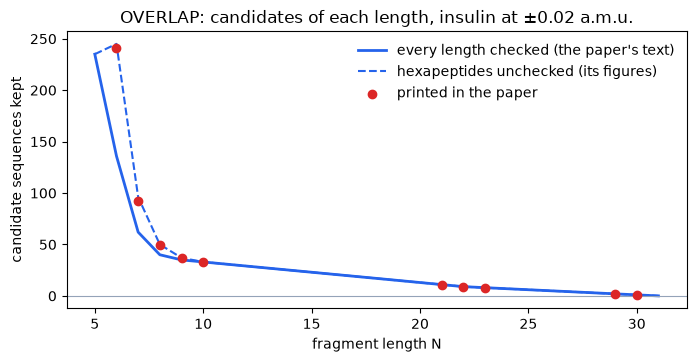

In [17]:
lengths = sorted(sizes)
figure, axes = plt.subplots(figsize=(8, 3.6))
axes.plot(
    lengths,
    [sizes[length] for length in lengths],
    color="#2563eb",
    lw=2,
    label="every length checked (the paper's text)",
)
axes.plot(
    lengths,
    [sizes_as_printed[length] for length in lengths],
    color="#2563eb",
    lw=1.5,
    linestyle="--",
    label="hexapeptides unchecked (its figures)",
)
axes.scatter(
    list(paper_with_fig9),
    list(paper_with_fig9.values()),
    color="#dc2626",
    zorder=3,
    s=36,
    label="printed in the paper",
)
axes.axhline(0, color="#94a3b8", lw=0.8)
axes.set_xlabel("fragment length N")
axes.set_ylabel("candidate sequences kept")
axes.set_title("OVERLAP: candidates of each length, insulin at ±0.02 a.m.u.")
axes.legend(frameon=False)
plt.show()

## The tryptophan misprint, demonstrated

Run the same lookup with the true tryptophan mass, and W (residue 186.079)
falls within 0.02 of the dipeptide G+E (186.064). Every "EG" in insulin then
also reads as a W.

In [18]:
# Free tryptophan at its true mass, as a residue of the paper's table.
free_tryptophan = MASSES["W"] + H2O
masses_true_w = dict(MASSES_1970, W=free_tryptophan - H2O_1970)
compositions_true_w = masfrg(observed, masses_true_w, H2O_1970, 4)
print(
    "with the printed W:",
    [len(compositions[length]) for length in (1, 2, 3)],
    " (paper: 16, 66, 197)",
)
print(
    "with the true W:   ",
    [len(compositions_true_w[length]) for length in (1, 2, 3)],
)
print(
    "\nanswer with the true W:",
    run(observed, masses_true_w, H2O_1970).chains(25),
)

with the printed W: [16, 66, 197]  (paper: 16, 66, 197)
with the true W:    [17, 71, 208]

answer with the true W: ['AKPTOFFGREGCVJOJAEVJHSGCJHQNVF', 'AKPTOFFGRWCVJOJAEVJHSGCJHQNVF']


## Resolution: ±0.02 against ±0.05

"If the maximum observable mass was limited to 1000 a.m.u., and the maximum
length of peptides to 9 links, the insulin problem could be solved with a
resolution of ±0.02 a.m.u., but could not be solved at ±0.05 a.m.u."

In [19]:
for tolerance in (0.02, 0.05):
    result = run(Observed(masses, tol_da=tolerance), MASSES_1970, H2O_1970)
    chains = result.chains(20)
    print(f"±{tolerance}: {len(chains)} chains of 20 residues or more")
    for chain in chains:
        print("   ", chain)

±0.02: 2 chains of 20 residues or more
    AKPTOFFGREGCVJOJAEVJHSGCJHQNVF
    GJVEQCCASVCSJOQJENOCN
±0.05: 12 chains of 20 residues or more
    AKPTOFFGREGCVJOJAEVJHSGCJHKNVF
    AKPTOFFGREGCVJOJAEVJHSGCJHQNVF
    AQPTOFFGREGCVJOJAEVJHSGCJHKNVF
    AQPTOFFGREGCVJOJAEVJHSGCJHQNVF
    GJVEKCCASVCSJOKJENOCN
    GJVEKCCASVCSJOQJENOCN
    GJVEQCCASVCSJOKJENOCN
    GJVEQCCASVCSJOQJENOCN
    NCONEJKOJSCVSACCKEVW
    NCONEJKOJSCVSACCQEVW
    NCONEJQOJSCVSACCKEVW
    NCONEJQOJSCVSACCQEVW


At ±0.05 glutamine and lysine (0.036 apart) can no longer be told apart, and
every Q/K position of the answer splits in two: four A chains, four B chains,
and some debris. The answer is not unique, so the problem is not solved.

## Practical considerations: noise


"Random noise masses can be tolerated in surprisingly large quantity because
the resulting peptides so seldom seem to overlap by chance ... If there were no
more than about 4000 actually observed masses in this range [100 to 1100],
including all noise, the spectrum would not be too crowded."

In [20]:
for n_noise in (0, 500, 1000, 2000, 4000, 8000):
    noisy = add_noise(masses, n_random=n_noise, lo=100, hi=1100, seed=0)
    result = run(
        Observed(noisy, tol_da=0.02),
        MASSES_1970,
        H2O_1970,
        max_list=300_000,
    )
    chains = result.chains(15)
    both_found = INSULIN_A in chains and (
        INSULIN_B in chains or INSULIN_B[::-1] in chains
    )
    print(
        f"{n_noise:5} noise masses ({len(noisy):5} in all): "
        f"{len(chains)} chains of 15+, both insulin chains found: "
        f"{both_found}"
        + ("" if result.converged else f"  [{result.reason}]")
    )

    0 noise masses (  302 in all): 2 chains of 15+, both insulin chains found: True
  500 noise masses (  802 in all): 2 chains of 15+, both insulin chains found: True
 1000 noise masses ( 1302 in all): 2 chains of 15+, both insulin chains found: True


 2000 noise masses ( 2302 in all): 2 chains of 15+, both insulin chains found: True
 4000 noise masses ( 4302 in all): 2 chains of 15+, both insulin chains found: True


 8000 noise masses ( 8302 in all): 2 chains of 15+, both insulin chains found: True


The reimplementation tolerates even more than the paper expected: both chains
still come back with 8000 random masses, twice the crowding the paper thought
the limit.

## Practical considerations: longer proteins

"We conclude that as an ideal problem, with true masses only, and no noise, a
protein of 100 links could be reconstructed, using the masses of fragments up
to only about 7 or 8 links long, having a maximum molecular mass in the order
of 800 a.m.u." Three random 100-residue proteins, exact masses, every fragment
below the mass limit:

In [21]:
letters = sorted(MASSES_1970)
for seed in (1, 2, 3):
    rng = random.Random(seed)
    protein = "".join(rng.choice(letters) for _ in range(100))
    row = []
    for limit in (700, 800, 1000):
        spectrum = Observed(
            ideal_masses([protein], 60, limit, MASSES_1970, H2O_1970),
            tol_da=0.001,
        )
        result = run(
            spectrum,
            MASSES_1970,
            H2O_1970,
            mass_limit=limit,
            max_list=300_000,
        )
        found = any(
            chain in (protein, protein[::-1])
            for chain in result.chains(100)
        )
        row.append(f"{limit}: {'solved' if found else 'not solved'}")
    print(f"protein {seed}:  " + ",  ".join(row))

protein 1:  700: not solved,  800: solved,  1000: solved


protein 2:  700: not solved,  800: not solved,  1000: solved
protein 3:  700: solved,  800: solved,  1000: solved


The paper's estimate holds: with masses up to about 800-1000 a.m.u. a
100-residue protein comes back from its fragment masses alone, and below that
it may not.

## And today?

The paper ends: "The actual characteristics of a working system will determine
the practicability of the whole scheme." The rest of this repository asks that
question of present-day instruments: `simulate.py` makes the mass list of an
LC-MS run of a non-specific digest, `modern.py` adapts the reconstruction to
it, and `scripts/real_pxd071026.py` runs it on a real pepsin digest of
myoglobin. The README summarises what came out: the accuracy is there (a few
ppm), but a standard proteomics or HDX run does not contain the many short,
overlapping fragments the method lives on.